# Big Data 04 · CRM turístico de San Luis Potosí
**ENTORNO ACADÉMICO — DATOS SINTÉTICOS**  
Universidad Rosario Castellanos · Ciencias de Datos para Negocios · Semestre 2026-2

Este cuaderno reconstruye ocho gráficas a partir de mediciones de Kafka y MongoDB. Cada fila corresponde a una corrida local completa. Las cifras de interacción proceden del simulador. En Colab se puede ejecutar todo desde el menú **Entorno de ejecución**. El archivo ya incluye la exportación agregada que acompaña al informe.

## Arquitectura, datos y contrato
El simulador toma destinos publicados y los ocho perfiles editoriales. Emite acciones por HTTP con una semilla. La API verifica la versión y el catálogo y espera el acuse de Kafka. El consumidor registra el evento canónico, su posición y las incidencias en MongoDB antes de confirmar el siguiente offset. El mismo reductor genera estados y atribución al recibir eventos y al reconstruir el corte. Parquet y DuckDB fijan las tablas exportadas. INAH y DataTur conservan sus granos recinto–mes y centro hotelero–mes.

La identidad del evento es estable al reenviarlo. La secuencia de cada actor ordena altas y bajas. Se considera elegible la exposición con al menos 50 % visible durante 1 000 ms continuos. Un clic exige correspondencia de impresión, actor, sesión, destino, campaña y familia. El periodo corresponde al tiempo de la impresión.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Opcional: coloque un archivo measurements.json autorizado junto al cuaderno.
path = Path('measurements.json')
embedded = json.loads('{"label":"ENTORNO ACADÉMICO — DATOS SINTÉTICOS","runs":[{"run":"run-04-1000a","at":"2026-11-25T14:52:36.883620+00:00","count":1000,"seed":42,"accepted":977,"rejected":23,"unique":950,"duplicates":27,"late_new":39,"errors":0,"latency_ms":{"mean":8511.942105263159,"method":"linear_interpolation","n":950,"p50":363,"p95":16836,"p99":16838},"elapsed_s":21.640582094000024,"throughput_e2e":43.899004004305084,"throughput_active":1123.7403757551238,"phases_s":{"generation":0.02717610699994566,"publication":0.19903332800004137,"validation":0.114204,"persistence":0.708,"query":0.09548531399991589,"dashboard":0.19307873100001416},"recovery_s":16.298118551000016,"recovery_lag":{"before":0,"during":500,"after":0},"final_lag":0,"resources":{"api":{"sample_count":10,"peak_sampled_bytes":208240640,"cpu_observed_s":9.181283},"broker":{"sample_count":10,"peak_sampled_bytes":705478656,"cpu_observed_s":5.882432},"consumer":{"sample_count":3,"peak_sampled_bytes":236818432,"cpu_observed_s":0.085347},"dashboard":{"sample_count":10,"peak_sampled_bytes":270991360,"cpu_observed_s":1.507482},"mongo":{"sample_count":10,"peak_sampled_bytes":554672128,"cpu_observed_s":1.858577}},"database_after":{"totals":{"active_ms":906.119,"batches":3,"input_attempts":997,"persistence_ms":764,"validation_ms":116.81299999999999},"storage_bytes":77824,"index_bytes":163840},"export_bytes":4638654,"cut":"4f48fd191f63018895284202","hashes":{"catalog":"3339e0873caac7c441b2b8ec7e9535ba96fd8211e03601327032c13e882832b0","controls":"5c5506eb0f75fd27f2b2d444d61f955d247729d122c5e2368e69a07b79eebadd","corpus":"c322b6fd5dd7193cc9fabcaec3d77e143a249f57c035007940134135aa8b98a1","results":"cbb6761349fdc513968ec041a4b62bc980aa9ac24081d90d12341741225402d6"},"campaign_metrics":[{"campaign_id":"camp-agua","click_actions":21,"clicked_impressions":14,"ctr_pct":37.83783783783784,"eligible_click_actions":14,"eligible_impressions":37,"family":"campaign"},{"campaign_id":"camp-cultura","click_actions":23,"clicked_impressions":16,"ctr_pct":42.10526315789474,"eligible_click_actions":16,"eligible_impressions":38,"family":"campaign"},{"campaign_id":"","click_actions":0,"clicked_impressions":0,"ctr_pct":null,"eligible_click_actions":0,"eligible_impressions":0,"family":"destination"},{"campaign_id":"camp-agua","click_actions":26,"clicked_impressions":14,"ctr_pct":38.888888888888886,"eligible_click_actions":14,"eligible_impressions":36,"family":"destination"},{"campaign_id":"camp-cultura","click_actions":30,"clicked_impressions":15,"ctr_pct":46.875,"eligible_click_actions":15,"eligible_impressions":32,"family":"destination"}],"states":{"favorites":{"active":27,"adds":41,"removes":14},"routes":{"active":41,"adds":59,"removes":18}},"recommendations":{"items_shown":238,"lists":120,"saved_actions":59},"policy_history":[{"access":"open","automatic_increase":false,"available":true,"capacity":10,"case":"B","destination_id":"H06","environmental_status":"clear","evaluated_at":"2026-11-25T14:52:04.845792Z","minimum_places":1,"places_available":6,"reason":"requiere_validacion_humana","recorded_at":"2026-11-25T14:52:04.845792Z","reservations":4,"revision":1,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"candidato","trigger_case":"B","trigger_revision":1,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:52:04.845792Z","valid_to":"2026-11-27T14:52:04.845792Z","verified":true},{"access":"open","automatic_increase":false,"available":true,"capacity":4,"case":"D","destination_id":"H06","environmental_status":"clear","evaluated_at":"2026-11-25T14:52:29.272172Z","minimum_places":1,"places_available":0,"reason":"cupo_insuficiente","recorded_at":"2026-11-25T14:52:29.272172Z","reservations":4,"revision":2,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"pausa","trigger_case":"D","trigger_revision":2,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:52:29.272172Z","valid_to":"2026-11-27T14:52:29.272172Z","verified":true},{"access":"open","automatic_increase":false,"available":true,"capacity":10,"case":"A","destination_id":"H07","environmental_status":"clear","evaluated_at":"2026-11-25T14:52:04.845792Z","minimum_places":1,"places_available":0,"reason":"cupo_insuficiente","recorded_at":"2026-11-25T14:52:04.845792Z","reservations":10,"revision":1,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"pausa","trigger_case":"A","trigger_revision":1,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:52:04.845792Z","valid_to":"2026-11-27T14:52:04.845792Z","verified":true}],"policy_counts":{"candidato":0,"pausa":2,"sin_datos":50,"bloqueado":0},"history":{"available":true,"database_name":"campaign.duckdb","label":"[OBSERVADO] Contexto oficial, lectura separada","sha256":"86a0cb77e60fcc14f346cdb9f06c3c8e43ed4338b8cd90145f8701ed6b2f7867","sources":{"DataTur":{"entities":1,"first_period":"2024-01-01","last_period":"2026-07-01","relation":"fact_datatur_occupancy_monthly","rows":31,"unit":"porcentaje hotelero del centro monitoreado por mes"},"INAH":{"entities":3,"first_period":"2015-01-01","last_period":"2026-08-01","relation":"fact_inah_visits_monthly","rows":420,"unit":"entradas registradas por recinto-mes"}}},"manifest":"exports/run-04-1000a/4f48fd191f63018895284202/manifest.json"},{"run":"run-04-10000a","at":"2026-11-25T14:54:41.490223+00:00","count":10000,"seed":42,"accepted":9793,"rejected":207,"unique":9490,"duplicates":303,"late_new":1254,"errors":0,"latency_ms":{"mean":7403.967439409905,"method":"linear_interpolation","n":9490,"p50":8556,"p95":13359.55,"p99":13427},"elapsed_s":17.500997332999987,"throughput_e2e":542.2548109361516,"throughput_active":943.5402984172387,"phases_s":{"generation":0.5712983609993216,"publication":3.3472686520002526,"validation":1.6875550000000001,"persistence":8.154,"query":0.07997441400004845,"dashboard":0.825525442000071},"recovery_s":null,"recovery_lag":{},"final_lag":0,"resources":{"api":{"sample_count":7,"peak_sampled_bytes":84144128,"cpu_observed_s":4.804795},"broker":{"sample_count":7,"peak_sampled_bytes":472739840,"cpu_observed_s":8.85318},"consumer":{"sample_count":7,"peak_sampled_bytes":243232768,"cpu_observed_s":6.6904829999999995},"dashboard":{"sample_count":7,"peak_sampled_bytes":353710080,"cpu_observed_s":5.060894},"mongo":{"sample_count":7,"peak_sampled_bytes":249442304,"cpu_observed_s":5.743157}},"database_after":{"totals":{"active_ms":11061.439999999997,"batches":24,"input_attempts":10820,"persistence_ms":9008,"validation_ms":1810.239},"storage_bytes":2117632,"index_bytes":909312},"export_bytes":5271051,"cut":"0b28e4636c07a28b8505e847","hashes":{"catalog":"3339e0873caac7c441b2b8ec7e9535ba96fd8211e03601327032c13e882832b0","controls":"236e80f5519161fb5200875b7b7ce79dca4682ccf33308d8a5ea1927ee417a1a","corpus":"869ad02a05f2b245e4bd5903c1c09bd42b7fc3f4e4d2f6db938284406444d9ff","results":"3464944fe711c1f1359dfadce2e46021ef4f2eaacf1246fbdbee5ddeacb80c53"},"campaign_metrics":[{"campaign_id":"camp-agua","click_actions":256,"clicked_impressions":153,"ctr_pct":44.606413994169095,"eligible_click_actions":153,"eligible_impressions":343,"family":"campaign"},{"campaign_id":"camp-cultura","click_actions":226,"clicked_impressions":124,"ctr_pct":37.920489296636084,"eligible_click_actions":124,"eligible_impressions":327,"family":"campaign"},{"campaign_id":"","click_actions":0,"clicked_impressions":0,"ctr_pct":null,"eligible_click_actions":0,"eligible_impressions":0,"family":"destination"},{"campaign_id":"camp-agua","click_actions":237,"clicked_impressions":142,"ctr_pct":41.15942028985507,"eligible_click_actions":142,"eligible_impressions":345,"family":"destination"},{"campaign_id":"camp-cultura","click_actions":236,"clicked_impressions":131,"ctr_pct":43.666666666666664,"eligible_click_actions":131,"eligible_impressions":300,"family":"destination"}],"states":{"favorites":{"active":282,"adds":456,"removes":174},"routes":{"active":407,"adds":636,"removes":229}},"recommendations":{"items_shown":2311,"lists":1169,"saved_actions":636},"policy_history":[{"access":"open","automatic_increase":false,"available":true,"capacity":10,"case":"B","destination_id":"H06","environmental_status":"clear","evaluated_at":"2026-11-25T14:54:12.867018Z","minimum_places":1,"places_available":6,"reason":"requiere_validacion_humana","recorded_at":"2026-11-25T14:54:12.867018Z","reservations":4,"revision":1,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"candidato","trigger_case":"B","trigger_revision":1,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:54:12.867018Z","valid_to":"2026-11-27T14:54:12.867018Z","verified":true},{"access":"open","automatic_increase":false,"available":true,"capacity":4,"case":"D","destination_id":"H06","environmental_status":"clear","evaluated_at":"2026-11-25T14:54:33.564116Z","minimum_places":1,"places_available":0,"reason":"cupo_insuficiente","recorded_at":"2026-11-25T14:54:33.564116Z","reservations":4,"revision":2,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"pausa","trigger_case":"D","trigger_revision":2,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:54:33.564116Z","valid_to":"2026-11-27T14:54:33.564116Z","verified":true},{"access":"open","automatic_increase":false,"available":true,"capacity":10,"case":"A","destination_id":"H07","environmental_status":"clear","evaluated_at":"2026-11-25T14:54:12.867018Z","minimum_places":1,"places_available":0,"reason":"cupo_insuficiente","recorded_at":"2026-11-25T14:54:12.867018Z","reservations":10,"revision":1,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"pausa","trigger_case":"A","trigger_revision":1,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:54:12.867018Z","valid_to":"2026-11-27T14:54:12.867018Z","verified":true}],"policy_counts":{"candidato":0,"pausa":2,"sin_datos":50,"bloqueado":0},"history":{"available":true,"database_name":"campaign.duckdb","label":"[OBSERVADO] Contexto oficial, lectura separada","sha256":"86a0cb77e60fcc14f346cdb9f06c3c8e43ed4338b8cd90145f8701ed6b2f7867","sources":{"DataTur":{"entities":1,"first_period":"2024-01-01","last_period":"2026-07-01","relation":"fact_datatur_occupancy_monthly","rows":31,"unit":"porcentaje hotelero del centro monitoreado por mes"},"INAH":{"entities":3,"first_period":"2015-01-01","last_period":"2026-08-01","relation":"fact_inah_visits_monthly","rows":420,"unit":"entradas registradas por recinto-mes"}}},"manifest":"exports/run-04-10000a/0b28e4636c07a28b8505e847/manifest.json"},{"run":"run-04-100000a","at":"2026-11-25T15:00:10.895427+00:00","count":100000,"seed":42,"accepted":98010,"rejected":1990,"unique":94999,"duplicates":3011,"late_new":13065,"errors":0,"latency_ms":{"mean":52138.60523794987,"method":"linear_interpolation","n":94999,"p50":49911,"p95":116176,"p99":122281},"elapsed_s":140.924941622,"throughput_e2e":674.110621630157,"throughput_active":1460.3239712105315,"phases_s":{"generation":2.235423582001772,"publication":13.24898110799893,"validation":12.014273999999993,"persistence":51.361,"query":0.11600958200006062,"dashboard":11.065184367000029},"recovery_s":null,"recovery_lag":{},"final_lag":0,"resources":{"api":{"sample_count":64,"peak_sampled_bytes":94396416,"cpu_observed_s":30.052109},"broker":{"sample_count":64,"peak_sampled_bytes":628416512,"cpu_observed_s":38.850107},"consumer":{"sample_count":64,"peak_sampled_bytes":307511296,"cpu_observed_s":34.553396},"dashboard":{"sample_count":64,"peak_sampled_bytes":1434140672,"cpu_observed_s":105.317831},"mongo":{"sample_count":64,"peak_sampled_bytes":504303616,"cpu_observed_s":55.976933}},"database_after":{"totals":{"active_ms":76181.06900000002,"batches":226,"input_attempts":108853,"persistence_ms":60432,"validation_ms":13826.614999999994},"storage_bytes":30294016,"index_bytes":18374656},"export_bytes":14169419,"cut":"d0d0c103c2c610332488cbeb","hashes":{"catalog":"3339e0873caac7c441b2b8ec7e9535ba96fd8211e03601327032c13e882832b0","controls":"ff7e277dfff85a62bb3461570961f544caa1b0fab01f2f7a9f52c3754201078e","corpus":"3f2f26d02378dbf53e21ace3c404c84b33860fb4d8081cd958803759abde1099","results":"c7d92fb77a25bfbd8aa1a4e38bc9f756a998deac09225765269603369223eda8"},"campaign_metrics":[{"campaign_id":"camp-agua","click_actions":2438,"clicked_impressions":1395,"ctr_pct":42.119565217391305,"eligible_click_actions":1395,"eligible_impressions":3312,"family":"campaign"},{"campaign_id":"camp-cultura","click_actions":2367,"clicked_impressions":1343,"ctr_pct":41.20895980362074,"eligible_click_actions":1343,"eligible_impressions":3259,"family":"campaign"},{"campaign_id":"","click_actions":0,"clicked_impressions":0,"ctr_pct":null,"eligible_click_actions":0,"eligible_impressions":0,"family":"destination"},{"campaign_id":"camp-agua","click_actions":2331,"clicked_impressions":1318,"ctr_pct":39.62717979555021,"eligible_click_actions":1318,"eligible_impressions":3326,"family":"destination"},{"campaign_id":"camp-cultura","click_actions":2316,"clicked_impressions":1270,"ctr_pct":39.56386292834891,"eligible_click_actions":1270,"eligible_impressions":3210,"family":"destination"}],"states":{"favorites":{"active":2641,"adds":4431,"removes":1790},"routes":{"active":3990,"adds":6385,"removes":2395}},"recommendations":{"items_shown":23212,"lists":11726,"saved_actions":6385},"policy_history":[{"access":"open","automatic_increase":false,"available":true,"capacity":10,"case":"B","destination_id":"H06","environmental_status":"clear","evaluated_at":"2026-11-25T14:57:05.598361Z","minimum_places":1,"places_available":6,"reason":"requiere_validacion_humana","recorded_at":"2026-11-25T14:57:05.598361Z","reservations":4,"revision":1,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"candidato","trigger_case":"B","trigger_revision":1,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:57:05.598361Z","valid_to":"2026-11-27T14:57:05.598361Z","verified":true},{"access":"open","automatic_increase":false,"available":true,"capacity":4,"case":"D","destination_id":"H06","environmental_status":"clear","evaluated_at":"2026-11-25T14:59:29.371765Z","minimum_places":1,"places_available":0,"reason":"cupo_insuficiente","recorded_at":"2026-11-25T14:59:29.371765Z","reservations":4,"revision":2,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"pausa","trigger_case":"D","trigger_revision":2,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:59:29.371765Z","valid_to":"2026-11-27T14:59:29.371765Z","verified":true},{"access":"open","automatic_increase":false,"available":true,"capacity":10,"case":"A","destination_id":"H07","environmental_status":"clear","evaluated_at":"2026-11-25T14:57:05.598361Z","minimum_places":1,"places_available":0,"reason":"cupo_insuficiente","recorded_at":"2026-11-25T14:57:05.598361Z","reservations":10,"revision":1,"rule_version":"capacity-gate-v1","source":"synthetic-operations-v1","status":"pausa","trigger_case":"A","trigger_revision":1,"unit":"plazas_simuladas","valid_from":"2026-11-25T14:57:05.598361Z","valid_to":"2026-11-27T14:57:05.598361Z","verified":true}],"policy_counts":{"candidato":0,"pausa":2,"sin_datos":50,"bloqueado":0},"history":{"available":true,"database_name":"campaign.duckdb","label":"[OBSERVADO] Contexto oficial, lectura separada","sha256":"86a0cb77e60fcc14f346cdb9f06c3c8e43ed4338b8cd90145f8701ed6b2f7867","sources":{"DataTur":{"entities":1,"first_period":"2024-01-01","last_period":"2026-07-01","relation":"fact_datatur_occupancy_monthly","rows":31,"unit":"porcentaje hotelero del centro monitoreado por mes"},"INAH":{"entities":3,"first_period":"2015-01-01","last_period":"2026-08-01","relation":"fact_inah_visits_monthly","rows":420,"unit":"entradas registradas por recinto-mes"}}},"manifest":"exports/run-04-100000a/d0d0c103c2c610332488cbeb/manifest.json"}]}')
experiment = json.loads(path.read_text(encoding='utf-8')) if path.is_file() else embedded
runs = sorted(experiment['runs'], key=lambda row: row['count'])
assert [r['count'] for r in runs] == [1000, 10000, 100000]
print(experiment['label'])
display(pd.DataFrame([{k:r[k] for k in ('run','seed','count','cut','at')} for r in runs]))

ENTORNO ACADÉMICO — DATOS SINTÉTICOS


,run,seed,count,cut,at
0,run-04-1000a,42,1000,4f48fd191f63018895284202,2026-11-25T14:52:36.883620+00:00
1,run-04-10000a,42,10000,0b28e4636c07a28b8505e847,2026-11-25T14:54:41.490223+00:00
2,run-04-100000a,42,100000,d0d0c103c2c610332488cbeb,2026-11-25T15:00:10.895427+00:00


## Calidad e idempotencia
La conciliación parte de los intentos publicados. Un rechazo de contrato queda en cuarentena. Una entrega aceptada puede repetir la identidad de un evento previo. El indicador de tardanza compara el tiempo de evento con el máximo anterior de su partición y la tolerancia de cinco segundos. Se verifica la conservación del corpus antes de graficarlo.

In [2]:
for r in runs:
    assert r['accepted'] + r['rejected'] == r['count']
    assert r['unique'] + r['duplicates'] == r['accepted'] and r['errors'] == 0
    assert r['final_lag'] == 0 and r['unique'] == r['latency_ms']['n']
display(pd.DataFrame([{k:r[k] for k in ('count','unique','duplicates','rejected','late_new','final_lag')} for r in runs]))

,count,unique,duplicates,rejected,late_new,final_lag
0,1000,950,27,23,39,0
1,10000,9490,303,207,1254,0
2,100000,94999,3011,1990,13065,0


### Verificación opcional del corte Parquet
Para reconciliar el corpus original, coloque la carpeta de un corte autorizado en `export/` en la sesión. Se comprueban las huellas del manifiesto y la unicidad de cada evento antes de consultar las tablas. En la modalidad autónoma se usan los agregados con las huellas del corte.

In [3]:
import hashlib
folder = Path('export')
if (folder / 'manifest.json').is_file():
    m = json.loads((folder/'manifest.json').read_text(encoding='utf-8'))
    r = next(row for row in runs if row['run'] == m['simulation_run_id'] and row['cut'] == m['cut_id'])
    assert m['hashes'] == r['hashes']
    for name, info in m['files'].items():
        assert Path(name).name == name
        assert hashlib.sha256((folder/name).read_bytes()).hexdigest() == info['sha256']
    ev = pd.read_parquet(folder/'events.parquet', columns=['simulation_run_id','event_id','cut_id'])
    assert ev['simulation_run_id'].unique().tolist() == [r['run']]
    assert ev['cut_id'].unique().tolist() == [r['cut']]
    assert len(ev) == ev['event_id'].nunique() == r['unique']
    display(pd.read_parquet(folder/'campaign_metrics.parquet'))
else:
    print('Modo autónomo con agregados de las tres corridas y hashes registrados.')

Modo autónomo con agregados de las tres corridas y hashes registrados.


## Rendimiento y escalabilidad
El rendimiento activo divide eventos únicos por tiempo activo del consumidor. El rendimiento extremo a extremo incluye la publicación y el drenaje, y en la corrida de recuperación también la pausa controlada. La latencia física parte del sello real de la API y termina al persistir el evento. Los percentiles usan interpolación lineal. Las tres escalas se midieron una vez en un nodo; la variabilidad entre réplicas queda abierta.

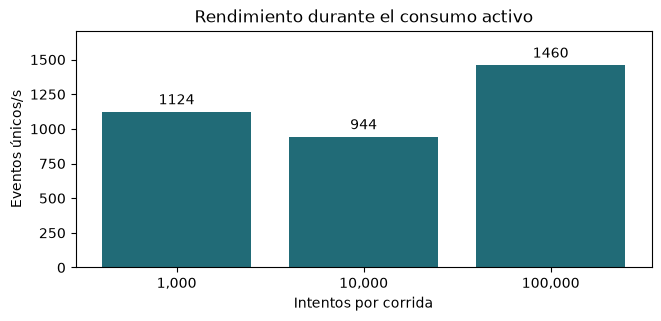

In [4]:
labels = [f"{r['count']:,}" for r in runs]
x = range(len(labels))
def count_chart(values, title, unit):
    fig, ax = plt.subplots(figsize=(6.5, 3.1), layout='constrained')
    bars = ax.bar(labels, values, color='#216b77')
    ax.bar_label(bars, fmt='%.0f', padding=3)
    ax.margins(y=.17)
    ax.set(title=title, xlabel='Intentos por corrida', ylabel=unit)
    plt.show()
count_chart([r['throughput_active'] for r in runs], 'Rendimiento durante el consumo activo', 'Eventos únicos/s')

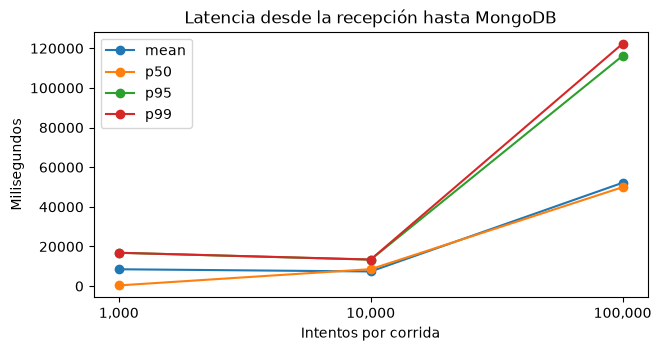

In [5]:
fig, ax = plt.subplots(figsize=(6.5,3.4), layout='constrained')
for metric in ('mean','p50','p95','p99'):
    ax.plot(labels, [r['latency_ms'][metric] for r in runs], 'o-', label=metric)
ax.set(title='Latencia desde la recepción hasta MongoDB', ylabel='Milisegundos', xlabel='Intentos por corrida')
ax.legend(); plt.show()

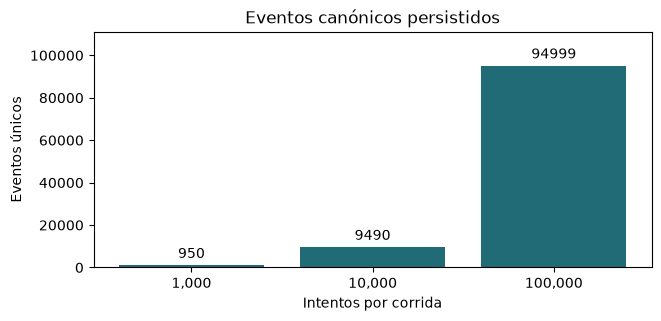

In [6]:
count_chart([r['unique'] for r in runs], 'Eventos canónicos persistidos', 'Eventos únicos')

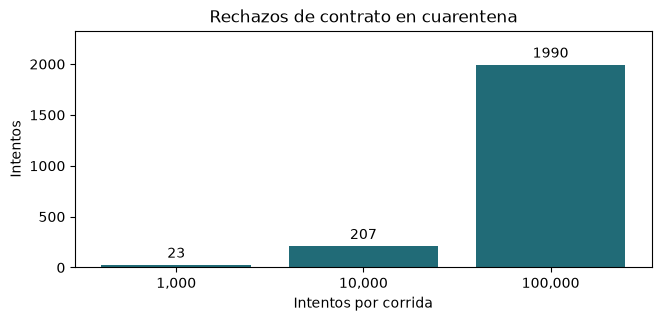

In [7]:
count_chart([r['rejected'] for r in runs], 'Rechazos de contrato en cuarentena', 'Intentos')

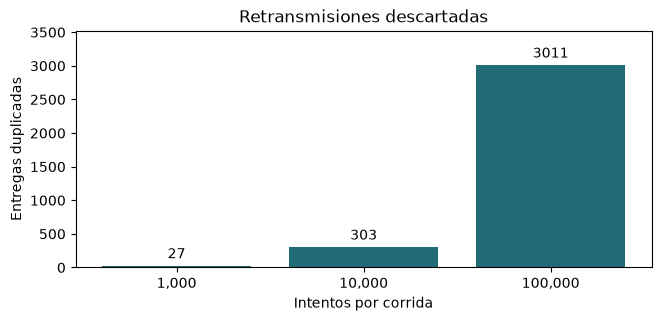

In [8]:
count_chart([r['duplicates'] for r in runs], 'Retransmisiones descartadas', 'Entregas duplicadas')

## Recuperación y reproducción
El consumidor se detuvo después de persistir un prefijo. El productor continuó publicando. Al reiniciar, Kafka reentregó lo pendiente. La suma de diferencias entre la posición final y la confirmada mide el rezago. Los hashes de corpus y resultados del manifiesto permiten contrastar el replay independiente al mismo instante de decisión.

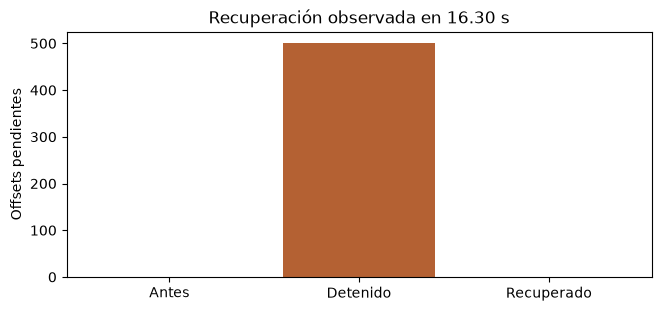

,corrida,catalog,controls,corpus,results
0,run-04-1000a,3339e0873caac7c441b2b8ec7e9535ba96fd8211e03601...,5c5506eb0f75fd27f2b2d444d61f955d247729d122c5e2...,c322b6fd5dd7193cc9fabcaec3d77e143a249f57c03500...,cbb6761349fdc513968ec041a4b62bc980aa9ac24081d9...
1,run-04-10000a,3339e0873caac7c441b2b8ec7e9535ba96fd8211e03601...,236e80f5519161fb5200875b7b7ce79dca4682ccf33308...,869ad02a05f2b245e4bd5903c1c09bd42b7fc3f4e4d2f6...,3464944fe711c1f1359dfadce2e46021ef4f2eaacf1246...
2,run-04-100000a,3339e0873caac7c441b2b8ec7e9535ba96fd8211e03601...,ff7e277dfff85a62bb3461570961f544caa1b0fab01f2f...,3f2f26d02378dbf53e21ace3c404c84b33860fb4d8081c...,c7d92fb77a25bfbd8aa1a4e38bc9f756a998deac092257...


In [9]:
r = next(r for r in runs if r['recovery_s'] is not None)
lag = r['recovery_lag']
assert lag['during'] > 0 and lag['after'] == 0
fig, ax = plt.subplots(figsize=(6.5,3), layout='constrained')
ax.bar(['Antes', 'Detenido', 'Recuperado'], [lag[k] for k in ('before','during','after')], color=['#216b77','#b46133','#216b77'])
ax.set(title=f"Recuperación observada en {r['recovery_s']:.2f} s", ylabel='Offsets pendientes')
plt.show()
display(pd.DataFrame([{'corrida':z['run'], **z['hashes']} for z in runs]))

## CRM y aplicación a campaña
El CTR divide impresiones elegibles con uno o más clics válidos entre impresiones elegibles. Un denominador vacío queda sin estimación. La comparación mantiene separadas la pauta y la tarjeta editorial. Las acciones de alta y baja se distinguen del estado activo final de cada ruta y favorito.

,campaign_id,click_actions,clicked_impressions,ctr_pct,eligible_click_actions,eligible_impressions,family
0,camp-agua,2438,1395,42.119565,1395,3312,campaign
1,camp-cultura,2367,1343,41.208960,1343,3259,campaign


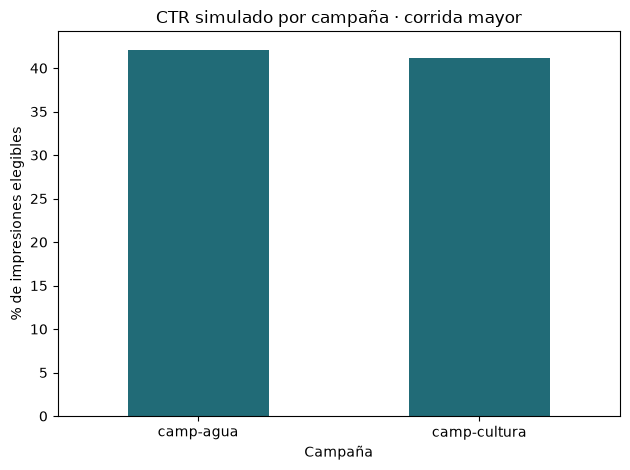

,active,adds,removes
favorites,2641,4431,1790
routes,3990,6385,2395


In [10]:
largest = runs[-1]
ads = pd.DataFrame([m for m in largest['campaign_metrics'] if m['family']=='campaign'])
assert (ads['clicked_impressions'] <= ads['eligible_impressions']).all()
display(ads)
ax = ads.plot.bar(x='campaign_id', y='ctr_pct', legend=False, color='#216b77', rot=0)
ax.set(title='CTR simulado por campaña · corrida mayor', xlabel='Campaña', ylabel='% de impresiones elegibles')
plt.tight_layout(); plt.show()
display(pd.DataFrame(largest['states']).T)

## Sustentabilidad y limitaciones
La elegibilidad exige fuente operativa simulada verificada, acceso abierto, ambiente adecuado, vigencia y al menos una plaza libre. H07 tiene cupo agotado. H06 comienza como candidato a revisión y cambia a pausa con la revisión D. Los destinos sin revisión conservan el estado sin datos. El ranking digital sirve para decidir qué creatividad ensayar después de verificar el destino. La reducción de presión turística y el retorno publicitario requerirían medición independiente en campo.

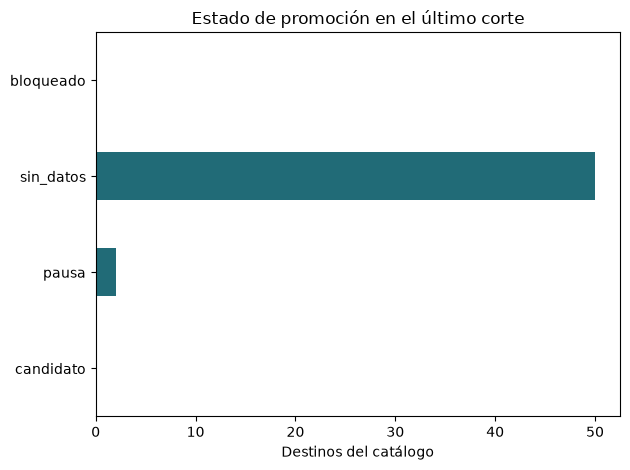

,destination_id,trigger_case,revision,capacity,reservations,status,reason
0,H06,B,1,10,4,candidato,requiere_validacion_humana
1,H06,D,2,4,4,pausa,cupo_insuficiente
2,H07,A,1,10,10,pausa,cupo_insuficiente


In [11]:
states = pd.Series(largest['policy_counts'], dtype=int)
ax = states.plot.barh(color='#216b77')
ax.set(title='Estado de promoción en el último corte', xlabel='Destinos del catálogo')
plt.tight_layout(); plt.show()
display(pd.DataFrame(largest['policy_history'])[['destination_id','trigger_case','revision','capacity','reservations','status','reason']])